# Project 7: Predictive Maintenance via Sensor Features and Sequence Models
Phase Two: engineered regression, LSTM and hybrid feature fusion.

Run cells in order. Saved results are loaded by default; set RETRAIN=True for the full experiment.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'phase2').exists():
    root = root.parent if root.name == 'phase2' else root.parents[1]
assert (root / 'phase2/pipeline.py').exists()
sys.path.insert(0, str(root))
from phase2.pipeline import *
from IPython.display import display, Image
RETRAIN = False
if RETRAIN:
    run()
r = ROOT / 'reports'

## Data quality and target definition
RUL is failure cycle minus current cycle for training engines only. The inherited cap is 125. Test endpoint labels are supplied separately. FD001 uses one regime.

In [2]:
train = load_data(ROOT / 'data/train_FD001.txt')
display(train.describe())
print('Training engines:', train.engine_id.nunique(), 'Rows:', len(train))
display(pd.read_csv(r / 'sensor_inspection.csv'))

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


Training engines: 100 Rows: 20631


,Unnamed: 0,training_std
0,sensor_1,1.136903e-13
1,sensor_2,5.047749e-01
2,sensor_3,6.144787e+00
3,sensor_4,9.054415e+00
4,sensor_5,3.552821e-15
5,sensor_6,1.437430e-03
6,sensor_7,8.925602e-01
7,sensor_8,7.259962e-02
8,sensor_9,2.196197e+01
9,sensor_10,4.441027e-16


## Engine split and leakage controls
Scalers and flat-sensor selection use only the 80 training engines. Padding and rolling features never cross engine boundaries. One fixed validation endpoint per engine mimics truncated evaluation.

In [3]:
manifest = json.loads((r / 'manifest.json').read_text())
assert set(manifest['train_engine_ids']).isdisjoint(manifest['validation_engine_ids'])
display(manifest)

{'seed_split': 2026,
 'train_engine_ids': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  12,
  14,
  15,
  16,
  19,
  21,
  22,
  23,
  24,
  25,
  27,
  28,
  29,
  30,
  31,
  33,
  34,
  35,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  46,
  48,
  49,
  50,
  51,
  53,
  54,
  55,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  66,
  67,
  68,
  69,
  70,
  72,
  73,
  74,
  75,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  86,
  87,
  88,
  90,
  91,
  93,
  94,
  95,
  96,
  97,
  99,
  100],
 'validation_engine_ids': [11,
  13,
  17,
  18,
  20,
  26,
  32,
  36,
  45,
  47,
  52,
  56,
  65,
  71,
  76,
  77,
  85,
  89,
  92,
  98],
 'validation_endpoints': [{'engine_id': 11, 'cycle': 209},
  {'engine_id': 13, 'cycle': 53},
  {'engine_id': 17, 'cycle': 36},
  {'engine_id': 18, 'cycle': 136},
  {'engine_id': 20, 'cycle': 104},
  {'engine_id': 26, 'cycle': 109},
  {'engine_id': 32, 'cycle': 42},
  {'engine_id': 36, 'cycle': 77},
  {'engine_id': 45, 'cycle': 113},
  {'e

## Architecture and training
30 × S sensors → LSTM(32) → regression head. Hybrid adds engineered features → Linear(16) → concatenation → regression head. MSE on RUL/125; AdamW, dropout, clipping and early stopping. LSTM1 and no-dropout runs isolate temporal history and head regularization.

In [4]:
prep = joblib.load(ROOT / 'models/preprocessing.joblib')
for f in [0, len(prep['feature_columns'])]:
    net = RULNet(len(prep['sensors']), f)
    print(net)
    print('Parameters:', sum(p.numel() for p in net.parameters()))
display(pd.read_csv(r / 'validation_metrics.csv'))

RULNet(
  (encoder): LSTM(15, 32, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
    (4): Sigmoid()
  )
)
Parameters: 7361
RULNet(
  (encoder): LSTM(15, 32, batch_first=True)
  (feature_branch): Sequential(
    (0): Linear(in_features=121, out_features=16, bias=True)
    (1): ReLU()
  )
  (head): Sequential(
    (0): Linear(in_features=48, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
    (4): Sigmoid()
  )
)
Parameters: 9825


,model,seed,n,rmse,mae,bias,nasa_score
0,RandomForest,42,20,13.472314,10.709676,4.558362,61.125118
1,LSTM30,42,20,16.122742,12.797432,4.789279,94.535771
2,LSTM30,43,20,15.402541,11.244864,2.639922,86.850509
3,LSTM30,44,20,15.161640,11.580248,5.479210,85.215783
4,Hybrid30,42,20,14.954872,11.933088,5.645350,79.610449
5,Hybrid30,43,20,13.635280,10.204239,5.218655,61.959755
6,Hybrid30,44,20,12.493876,8.543971,2.999421,51.564890
7,LSTM1,42,20,22.673435,14.973784,6.289102,1191.871224
8,LSTM1,43,20,22.296522,14.684321,6.513864,1127.961083
9,LSTM1,44,20,22.488527,14.792440,6.846990,1314.282004


## Fair test comparison
Same test endpoints, cap and training engines for every model. Mean and standard deviation across three neural seeds; Random Forest has one seed. Phase One all-engine metrics are historical context, not the fair comparison.

rmse                  mae          
                                 mean       std       mean       std
model             target                                            
Hybrid30          capped    14.510121  0.724178  10.427436  0.381460
                  uncapped  15.517250  0.652635  11.497436  0.381460
LSTM1             capped    16.747101  0.051217  11.521997  0.025282
                  uncapped  17.720986  0.041620  12.591997  0.025282
LSTM30            capped    14.584881  0.665787  10.759540  0.420893
                  uncapped  15.678372  0.649381  11.829540  0.420893
LSTM30_no_dropout capped    14.147410  0.748170  10.329078  0.392846
                  uncapped  15.342778  0.674803  11.399078  0.392846
RandomForest      capped    12.953466       NaN   9.318167       NaN
                  uncapped  14.155620       NaN  10.388167       NaN

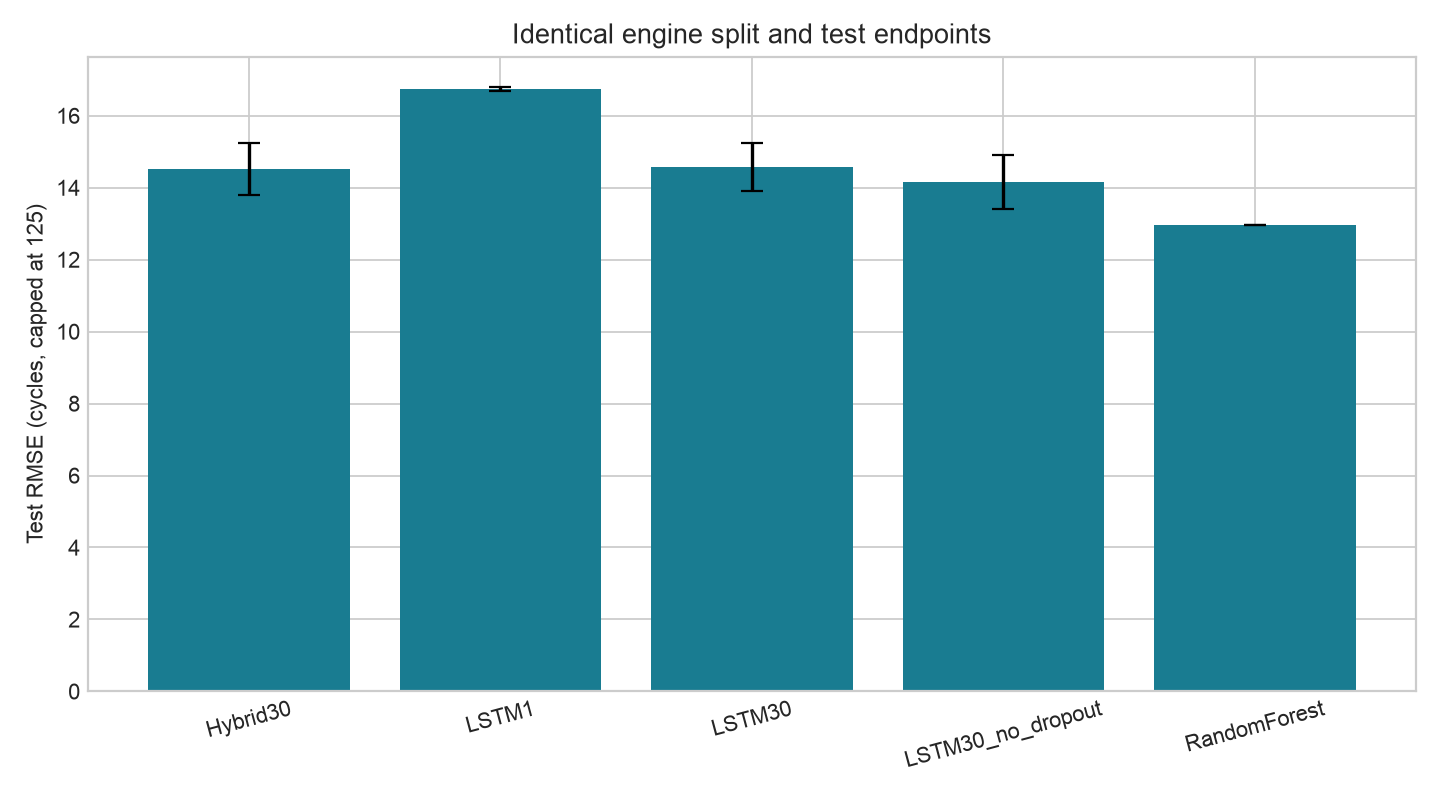

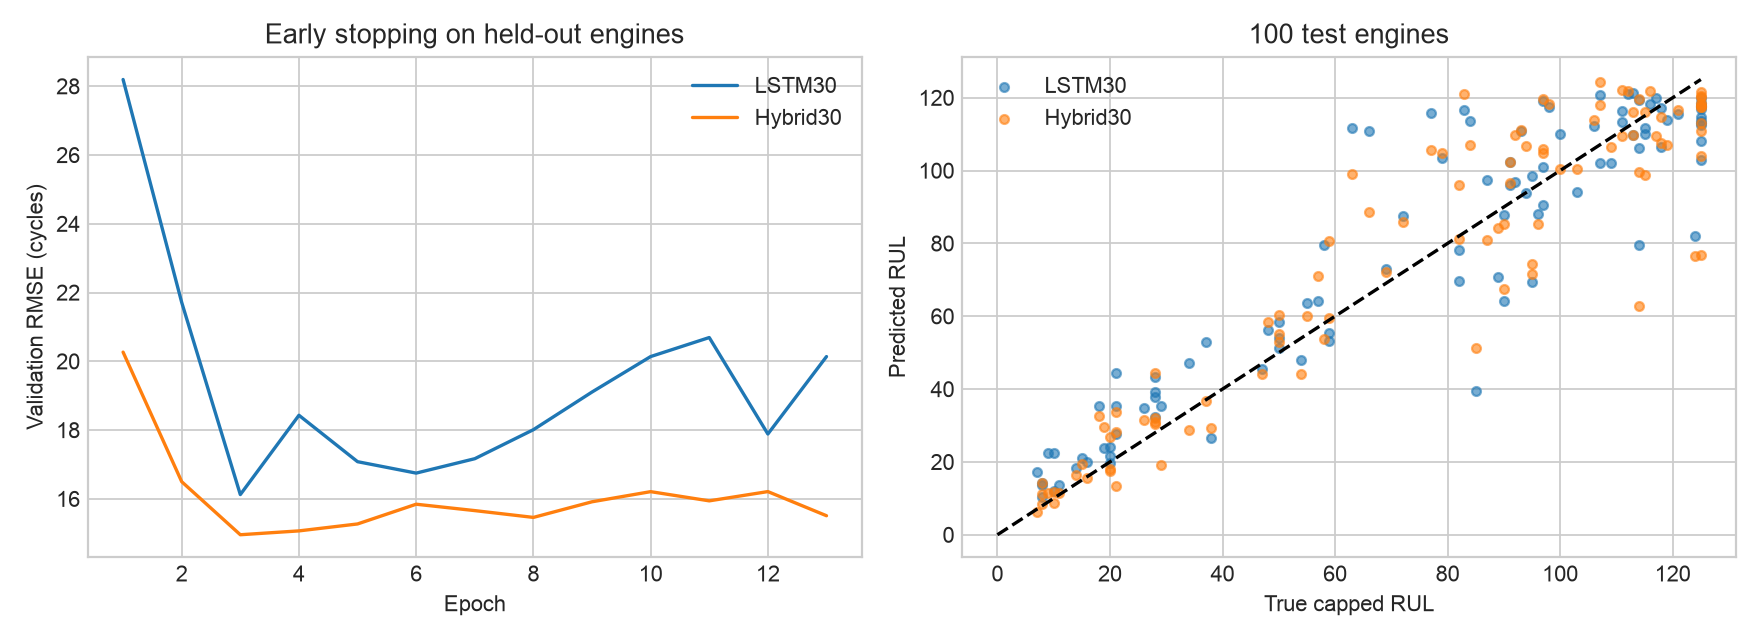

In [5]:
scores = pd.read_csv(r / 'test_metrics.csv')
display(scores.groupby(['model','target'])[['rmse','mae']].agg(['mean','std']))
display(Image(filename=str(r / 'comparison.png')))
display(Image(filename=str(r / 'diagnostics.png')))

## Error by degradation stage
Stages are defined from uncapped truth: late ≤30, middle 31–90, early >90. Positive bias means overestimated remaining life.

rmse        mae      bias
model             target   stage                                        
Hybrid30          capped   early_over_90  16.488702  12.690944 -3.539124
                           late_0_30       5.029332   3.995682  1.461275
                           middle_31_90   16.459010  12.381660  2.843497
                  uncapped early_over_90  18.377122  15.017031 -5.865211
                           late_0_30       5.029332   3.995682  1.461275
                           middle_31_90   16.459010  12.381660  2.843497
LSTM1             capped   early_over_90  14.369127  10.420596 -2.649006
                           late_0_30      14.597072   8.884957  7.872673
                           middle_31_90   21.352120  15.542356  8.780294
                  uncapped early_over_90  16.716654  12.746683 -4.975093
                           late_0_30      14.597072   8.884957  7.872673
                           middle_31_90   21.352120  15.542356  8.780294
LSTM30            capped   early_over_90  13.211259  10.529103 -1.931259
                           late_0_30       6.887395   5.607461  5.240590
                           middle_31_90   20.299495  15.566508  7.536427
                  uncapped early_over_90  15.702077  12.855190 -4.257346
                           late_0_30       6.887395   5.607461  5.240590
                           middle_31_90   20.299495  15.566508  7.536427
LSTM30_no_dropout capped   early_over_90  13.650274  11.057731 -1.908945
                           late_0_30       5.060874   4.061564  3.233645
                           middle_31_90   19.168264  14.576312  6.090060
                  uncapped early_over_90  16.209856  13.383818 -4.235032
                           late_0_30       5.060874   4.061564  3.233645
                           middle_31_90   19.168264  14.576312  6.090060
RandomForest      capped   early_over_90  14.326502  11.117255 -2.511772
                           late_0_30       5.881595   4.278882  3.698871
                           middle_31_90   14.940065  10.808654  3.990782
                  uncapped early_over_90  16.616106  13.443342 -4.837859
                           late_0_30       5.881595   4.278882  3.698871
                           middle_31_90   14.940065  10.808654  3.990782

,model,seed,engine_id,cycle,actual_rul,capped_rul,predicted_rul
0,RandomForest,42,1,31,112.0,112.0,123.089750
1,RandomForest,42,2,49,98.0,98.0,121.333255
2,RandomForest,42,3,126,69.0,69.0,59.692563
3,RandomForest,42,4,106,82.0,82.0,86.559748
4,RandomForest,42,5,98,91.0,91.0,82.011083
5,RandomForest,42,6,105,93.0,93.0,115.015499
6,RandomForest,42,7,160,91.0,91.0,109.361096
7,RandomForest,42,8,166,95.0,95.0,85.346128
8,RandomForest,42,9,55,111.0,111.0,120.604919
9,RandomForest,42,10,192,96.0,96.0,94.785649


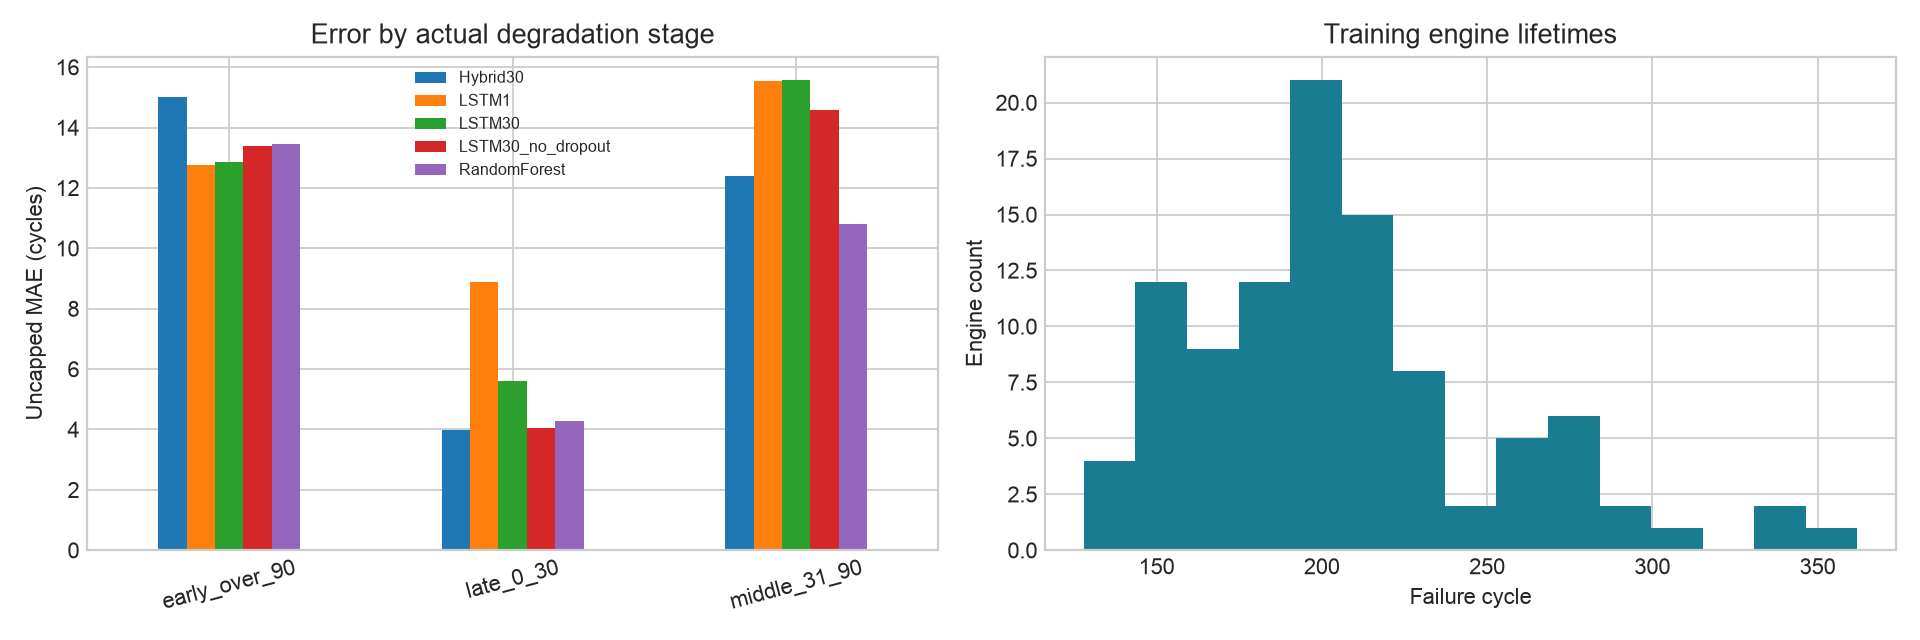

In [6]:
display(pd.read_csv(r / 'stage_metrics.csv').groupby(['model','target','stage'])[['rmse','mae','bias']].mean())
display(pd.read_csv(r / 'engine_predictions.csv').head(15))
display(Image(filename=str(r / 'stages_and_lifetimes.png')))

## Hybrid evidence and limitations
The paired interval includes zero; a reliable hybrid advantage is not established.

The paired interval uses seed-ensemble predictions and resamples engines, not windows. Single split, small validation set, simulation domain, target cap and overlapping windows limit interpretation.

In [7]:
print('Validation-selected model:', manifest['selected_by_validation'])
print('Hybrid minus LSTM ensemble RMSE 95% interval:', manifest['hybrid_minus_lstm_ensemble_rmse_bootstrap_95ci'])

Validation-selected model: RandomForest
Hybrid minus LSTM ensemble RMSE 95% interval: [-2.5360159930882946, 1.997455961511446]


## Saved-checkpoint inference
No test labels are needed to predict RUL from sensor histories.

In [8]:
from phase2.predict import predict_file
predictions = predict_file(ROOT / 'data/test_FD001.txt', ROOT / 'models/LSTM30_42.pt', r / 'inference.csv')
display(predictions.head())
assert len(predictions) == 100

,engine_id,cycle,predicted_rul
30,1,31,120.957367
79,2,49,117.316719
205,3,126,72.942940
311,4,106,69.607887
409,5,98,96.082855


## References
1. [NASA C-MAPSS repository](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/)
2. [Hochreiter & Schmidhuber, 1997](https://doi.org/10.1162/neco.1997.9.8.1735)
3. [Bai et al., 2018](https://arxiv.org/abs/1803.01271)

See submission/report.tex for the IEEE-format source and VIVA.md for individual preparation.